In [16]:
from typing import Literal, Sequence, TypeVar, overload

import numpy as np
import numpy.typing as npt
from scipy.optimize import linear_sum_assignment
from tqdm.notebook import tqdm

In [1]:
!pip uninstall -y starktools
!pip install git+https://github.com/lukelbro/starktools

Found existing installation: starktools 0.1.16.1
Uninstalling starktools-0.1.16.1:
  Successfully uninstalled starktools-0.1.16.1
  Cloning https://github.com/lukelbro/starktools to /private/var/folders/r2/t3r1qk8s2xxdgx77f9qldlvw0000gn/T/pip-req-build-99seylg3
  Running command git clone --filter=blob:none --quiet https://github.com/lukelbro/starktools /private/var/folders/r2/t3r1qk8s2xxdgx77f9qldlvw0000gn/T/pip-req-build-99seylg3
  Resolved https://github.com/lukelbro/starktools to commit 32aaed6b92a7697fbe5ac5191e1bc19a82c2a218
  Preparing metadata (setup.py) ... done
  Created wheel for starktools: filename=starktools-0.1.16.1-py3-none-any.whl size=20125 sha256=19b4165899c8eb287f2fe9bc1a8ddc51dab1a7242c40201d9a5c80a9dd087423
  Stored in directory: /private/var/folders/r2/t3r1qk8s2xxdgx77f9qldlvw0000gn/T/pip-ephem-wheel-cache-e3f8ywrm/wheels/a9/33/1b/614dbd5670e439fe77647611854f31b19442817b1bd424cdcc
Successfully built starktools


In [17]:
import starktools

In [29]:
nmin = 5
nmax = 5
q = 1
freq = 3.35e9* starktools.Constants.h /starktools.Constants.E_He

In [28]:
h0 = starktools.MatrixFsH0Floquet(nmin, nmax, 1, 0 , q, freq).matrix.astype(np.float64)
hf = starktools.MatrixFsHfFloquet(nmin, nmax, 1, 0 , q, freq).matrix.astype(np.float64) * 1/starktools.Constants.F_He
hs = starktools.MatrixFsHsFloquet(nmin, nmax, 1, 0, q, freq).matrix.astype(np.float64) * 1/starktools.Constants.F_He

In [20]:
h0 = starktools.MatrixFsH0Floquet(nmin, nmax, 1, 0 , 1, freq).matrix.astype(np.float64)


In [27]:
h0

array([[-0.02261981,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        , -0.0226193 ,  0.        , ...,  0.        ,
         0.        ,  0.        ],
       [ 0.        ,  0.        , -0.02261879, ...,  0.        ,
         0.        ,  0.        ],
       ...,
       [ 0.        ,  0.        ,  0.        , ..., -0.02000127,
         0.        ,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
        -0.02000076,  0.        ],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        , -0.02000025]], shape=(225, 225))

In [30]:
h1 = h0 + hf + hs


In [31]:
h2 = h0 + hf*1.1 + hs


In [19]:
from scipy.sparse.linalg import eigsh
import scipy.sparse as sp

k = 2000
eigenvalues, eigenvectors = eigsh(h1, k=k, which='SA')  # SA = Smallest Algebraic

KeyboardInterrupt: 

In [18]:
eigenvectors.shape

(37500, 2)

In [66]:
h1.shape

(37500, 37500)

In [32]:
u1, v1 = np.linalg.eigh(h1)
u2, v2 = np.linalg.eigh(h2)  

In [33]:
distance = 1 - np.abs(v1.T @ v2)

In [30]:
from scipy.optimize import linear_sum_assignment

In [56]:
_, col_ind = linear_sum_assignment(distance)

In [32]:
from sslap import auction_solve

In [57]:
auction_solve(distance, problem='min')

{'sol': array([    0,     1,     2, ..., 11022, 11023, 11024],
       shape=(11025,), dtype=int32),
 'meta': {'start_eps': 0.5,
  'eCE': 1,
  'its': 666,
  'nreductions': 5,
  'soln_found': 1,
  'n_assigned': 11025,
  'obj': 2461.843,
  'final_eps': 0.0,
  'timer': {'setup': '495.60ms', 'solve': '728.50ms'}}}

In [14]:
u, v = np.linalg.eig(h)
args = np.argsort(u.real)
u = u[args]
v = v[:, args]
inv_vs = np.linalg.inv(v)
indx_map_v = np.argmax(np.abs(inv_vs) ** 2, axis=0)

v1 = v


In [16]:
h = h0 + hf + hs*1.1

u, v = np.linalg.eig(h)
args = np.argsort(u.real)
u = u[args]
v = v[:, args]
inv_vs = np.linalg.inv(v)
indx_map_v = np.argmax(np.abs(inv_vs) ** 2, axis=0)

v2 = v


In [19]:
v1.T.shape

(900, 900)

In [23]:
1 - np.abs((v1.T @ v2))

array([[0.0000000e+00, 1.0000000e+00, 9.9999994e-01, ..., 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00],
       [1.0000000e+00, 9.9766254e-04, 9.7350872e-01, ..., 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00],
       [1.0000000e+00, 7.5422609e-01, 2.6365817e-02, ..., 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00],
       ...,
       [1.0000000e+00, 1.0000000e+00, 1.0000000e+00, ..., 1.0000000e+00,
        1.0000000e+00, 1.0000000e+00],
       [1.0000000e+00, 1.0000000e+00, 1.0000000e+00, ..., 9.9328142e-01,
        1.0000000e+00, 1.0000000e+00],
       [1.0000000e+00, 1.0000000e+00, 1.0000000e+00, ..., 1.0000000e+00,
        1.0000000e+00, 0.0000000e+00]], shape=(900, 900), dtype=float32)

In [24]:
u2, v2 = np.linalg.eigh(h)
args2 = np.argsort(u2.real)
u2 = u2[args2]
v2 = v2[:, args2]

inv_vs = np.linalg.inv(v2)
indx_map_v2 = np.argmax(np.abs(inv_vs) ** 2, axis=0)

In [25]:
indx_map_v2

array([  0,   3,   6,   1,   4,   7,   2,   5,   8,  17,  26,  35,  15,
        25,  32,  16,  23,  33,  14,  24,  34,   9,  18,  27,  10,  19,
        31,  11,  20,  30,  12,  21,  28,  13,  22,  29,  50,  64,  80,
        49,  65,  79,  48,  63,  78,  44,  61,  77,  45,  51,  76,  43,
        57,  74,  46,  60,  73,  47,  59,  75,  36,  58,  66,  37,  62,
        70,  38,  56,  69,  39,  54,  71,  40,  53,  72,  41,  52,  68,
        42,  55,  67,  99, 374, 644, 100, 370, 647, 101, 371, 643,  98,
       372, 646,  97, 373, 645,  87, 354, 628,  86, 359, 630,  85, 355,
       631,  84, 356, 632,  83, 357, 633,  82, 360, 627,  81, 358, 629,
        88, 368, 635,  89, 367, 637,  90, 362, 636,  91, 366, 640,  92,
       369, 634,  93, 364, 638,  94, 365, 641,  95, 361, 639,  96, 363,
       642, 127, 398, 671, 126, 397, 670, 128, 396, 668, 125, 400, 673,
       124, 399, 672, 123, 401, 669, 122, 395, 674, 102, 376, 654, 103,
       382, 656, 104, 381, 652, 105, 379, 651, 106, 380, 655, 10

In [23]:
indx_map_v 

array([  0,   3,   6,   1,   4,   7,   2,   5,   8,  17,  26,  35,  16,
        25,  33,  14,  24,  34,  15,  23,  32,  13,  20,  27,   9,  21,
        29,  10,  19,  30,  11,  18,  31,  12,  22,  28,  48,  63,  80,
        49,  64,  79,  50,  65,  78,  43,  60,  77,  47,  56,  76,  46,
        61,  75,  45,  62,  74,  44,  57,  73,  38,  55,  71,  37,  54,
        70,  36,  52,  72,  41,  53,  66,  39,  59,  67,  40,  51,  68,
        42,  58,  69,  99, 370, 646, 100, 371, 643,  97, 372, 645, 101,
       374, 644,  98, 373, 647,  86, 360, 627,  81, 359, 629,  82, 355,
       633,  83, 358, 631,  84, 356, 630,  85, 357, 628,  87, 354, 632,
        90, 363, 642,  95, 367, 641,  94, 364, 640,  96, 368, 637,  92,
       365, 638,  93, 362, 639,  88, 366, 635,  89, 369, 634,  91, 361,
       636, 125, 398, 669, 126, 400, 670, 123, 399, 671, 124, 397, 672,
       122, 401, 673, 128, 396, 674, 127, 395, 668, 102, 381, 656, 103,
       376, 654, 104, 375, 648, 105, 377, 653, 107, 380, 652, 10

In [6]:
from matplotlib import pyplot as plt

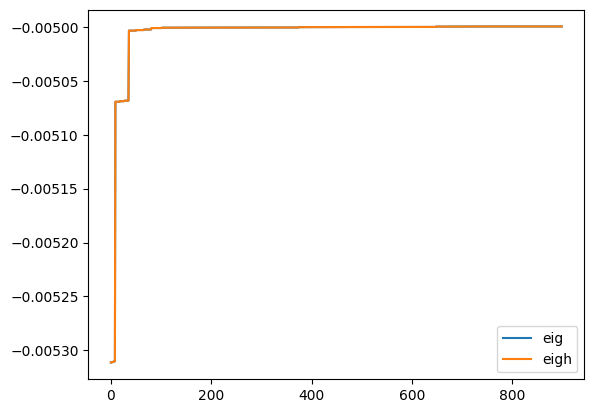

In [47]:
plt.plot(u, label='eig')
plt.plot(u2, label='eigh')

plt.legend()

In [78]:
import starktools
from eigenshuffle_functions import eigenshuffle_eigvals, eigenshuffle_eigvals, eigenshuffle_eighvals, eigenshuffle_eig, eigenshuffle_eigh
import numpy as np

In [71]:
nmin = 20
nmax = 20
q = 1
freq = 300.35e9* starktools.Constants.h /starktools.Constants.E_He

def hamiltonian(v,f):
    h0 = starktools.MatrixFsH0Floquet(nmin, nmax, 1, 0 , q, freq).matrix.astype(np.float32)
    hf = starktools.MatrixFsHfFloquet(nmin, nmax, 1, 0 , q, freq).matrix.astype(np.float32) * v/starktools.Constants.F_He
    hs = starktools.MatrixFsHsFloquet(nmin, nmax, 1, 0, q, freq).matrix.astype(np.float32) * f/starktools.Constants.F_He 
    
    return h0 + hf + hs

In [80]:
vacs = list(np.linspace(0, 360.421087, 10)) + list([360.421087]*20)
field_abs = list([0]*10) + list(np.linspace(0, 1500000, 20)/10)


h = [hamiltonian(v, f) for v, f in zip(vacs, field_abs)]
def mat_factory(i):
    v = vacs[i]
    f = field_abs[i]
    return hamiltonian(v,f).astype(np.float32)

In [81]:
arr = np.array(h)

In [82]:
es_x, indx_map = eigenshuffle_eighvals(
    mat_factory,
    count = len(vacs),
    dtype= np.float32,
    use_eigenvalues=False
)

Generating matrix elements..
Diagonalizing first matrix...
Calculating state mapping
(a) inverting eigenvector matrix
(b) calculating abs(v)^2 and argmax on CPU
(c) mapping state indices


Time to complete eigval diag+shuffle:   3%|▎         | 1/29 [00:00<00:04,  6.30matrix/s]

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:   0%|          | 0/29 [00:00<?, ?matrix/s]
Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:   3%|▎         | 1/29 [00:00<00:04,  6.30matrix/s]


Time to complete eigval diag+shuffle:   7%|▋         | 2/29 [00:00<00:04,  6.34matrix/s]

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:   7%|▋         | 2/29 [00:00<00:04,  6.34matrix/s]


...

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:  86%|████████▌ | 25/29 [00:04<00:00,  5.93matrix/s]


Time to complete eigval diag+shuffle:  93%|█████████▎| 27/29 [00:05<00:00,  3.68matrix/s]

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:  90%|████████▉ | 26/29 [00:04<00:00,  3.30matrix/s]
Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:  93%|█████████▎| 27/29 [00:05<00:00,  3.68matrix/s]


Time to complete eigval diag+shuffle: 100%|██████████| 29/29 [00:05<00:00,  5.27matrix/s]

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:  97%|█████████▋| 28/29 [00:05<00:00,  4.16matrix/s]


In [8]:
es_x, indx_map = eigenshuffle_eighvals(
    mat_factory,
    count = len(vacs),
    dtype= np.float32,
    use_eigenvalues=False, 
    use_jax=True
)

Generating matrix elements..
Diagonalizing first matrix...
Calculating state mapping
(a) inverting eigenvector matrix
(b) calculating abs(v)^2 and argmax on CPU
(c) mapping state indices


Time to complete eigval diag+shuffle:   0%|          | 0/29 [00:00<?, ?matrix/s]

In [10]:
es_x, indx_map = eigenshuffle_eighvals(
    mat_factory,
    count = len(vacs),
    dtype= np.float32,
    use_eigenvalues=False, 
    use_jax=False
)

Generating matrix elements..
Diagonalizing first matrix...
Calculating state mapping
(a) inverting eigenvector matrix
(b) calculating abs(v)^2 and argmax on CPU
(c) mapping state indices


Time to complete eigval diag+shuffle:   0%|          | 0/29 [00:00<?, ?matrix/s]

In [42]:
conversion_to_wn = starktools.Constants.E_He/starktools.Constants.h

In [43]:
from matplotlib import pyplot as plt

In [44]:
states = list(starktools.basis_fs.generate_atom_levels_fs_floquet(nmin, nmax, 1, 1))


/var/folders/r2/t3r1qk8s2xxdgx77f9qldlvw0000gn/T/ipykernel_64243/56368055.py:8: MatplotlibDeprecationWarning: Passing label as a length 6 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot( es_x.real[:, i]*conversion_to_wn/10**9, linewidth=0.7, color='black', zorder=1, label=state, alpha =0.9)
/var/folders/r2/t3r1qk8s2xxdgx77f9qldlvw0000gn/T/ipykernel_64243/56368055.py:6: MatplotlibDeprecationWarning: Passing label as a length 6 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot( es_x.real[:, i]*conversion_to_wn/10**9, linewidth=0.7, color='tab:blue', zorder=3, label=state)


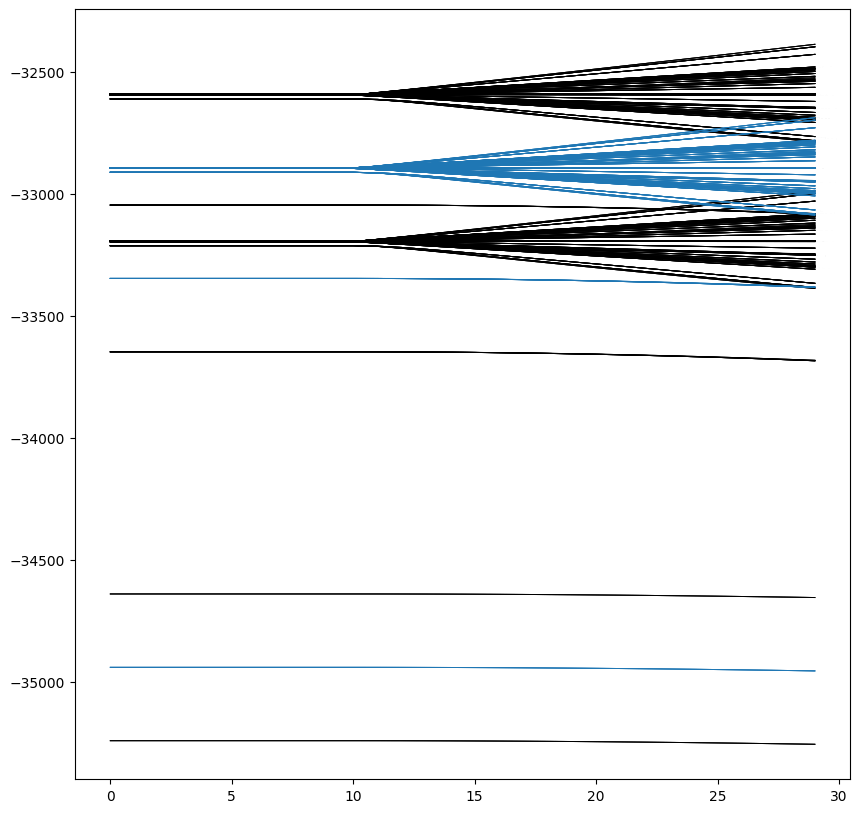

In [45]:
#increase figure size
plt.figure(figsize=(10, 10))
for i in range(es_x.shape[-1]):
    state = states[indx_map[i]]
    if state[-1] == 0:
        plt.plot( es_x.real[:, i]*conversion_to_wn/10**9, linewidth=0.7, color='tab:blue', zorder=3, label=state)
    else:
        plt.plot( es_x.real[:, i]*conversion_to_wn/10**9, linewidth=0.7, color='black', zorder=1, label=state, alpha =0.9)



In [48]:
es_a, vs = eigenshuffle_eig(
    arr,
    dtype= np.float32
)

Time to complete diagonalization:   0%|          | 0/30 [00:00<?, ?matrix/s]

/Users/lukebrown/Downloads/eigenshuffle-main/eigenshuffle/eigenshuffle_functions.py:227: ComplexWarning: Casting complex values to real discards the imaginary part
  eigenvalues[i] = vals
/Users/lukebrown/Downloads/eigenshuffle-main/eigenshuffle/eigenshuffle_functions.py:228: ComplexWarning: Casting complex values to real discards the imaginary part
  eigenvectors[i] = vecs


Time to complete shuffle:   0%|          | 0/29 [00:00<?, ?pair/s]

In [25]:
import mlx.core as mx

In [26]:
A = mx.array([[1., -2.], [-2., 1.]])
w, v = mx.linalg.eigh(A, stream=mx.gpu)

ValueError: [linalg::eigh] This op is not yet supported on the GPU. Explicitly pass a CPU stream to run it.

In [12]:
states_gen = list(starktools.basis_fs.generate_atom_levels_fs_floquet(nmin, nmax, 1, 1))


def vectorized_process_states(vs):
    # inv_vs.dot(e_i) equals the i-th column, so we process all columns at once.
    inv_vs = np.linalg.inv(vs[0])
    # Compute squared absolute values and then the argmax along rows for each column.
    indices = np.argmax(np.abs(inv_vs)**2, axis=0)
    return indices

# Usage in your notebook:
indices = vectorized_process_states(vs)

states = {ind: state for ind, state in zip(indices, states_gen)}



In [69]:
indx_map[100]

np.int64(342)

In [59]:
from tqdm import tqdm
import time

class LineLoggingTQDM(tqdm):
    def display(self, msg=None, pos=None):
        # Use tqdm's built-in formatting for desc, ETA, etc.
        if msg is None:
            msg = self.format_meter(**self.format_dict)
        self.write(f"{self.desc or ''} | {msg}", end="\n")

# Example usage:
iterator = LineLoggingTQDM(range(1), desc="Time to complete eigval diag+shuffle", unit="matrix", mininterval=1.0)

for i in iterator:
    time.sleep(0.2)  # simulate work

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:   0%|          | 0/1 [00:00<?, ?matrix/s]
Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle: 100%|██████████| 1/1 [00:00<00:00,  4.87matrix/s]


In [70]:
indices[100]

np.int64(342)

In [ ]:
states_gen[0]

(10, 1, 1, 2, -1, 1)

In [78]:
np.argwhere(indices == 10)[0]

array([33])

In [79]:
inverse_map = {val: idx for idx, val in enumerate(indx_map)}


In [ ]:
indices[10]

np.int64(26)

In [72]:
states[10]

(10, 1, 1, 2, 2, -1)

In [66]:
states = {}
for ind, state in zip(indx_map, states_gen):
    print(ind, state)
    states[ind] = state

0 (10, 0, 1, 1, -1, -1)
3 (10, 0, 1, 1, -1, 0)
6 (10, 0, 1, 1, -1, 1)
1 (10, 0, 1, 1, 0, -1)
4 (10, 0, 1, 1, 0, 0)
7 (10, 0, 1, 1, 0, 1)
2 (10, 0, 1, 1, 1, -1)
5 (10, 0, 1, 1, 1, 0)
8 (10, 0, 1, 1, 1, 1)
17 (10, 1, 1, 0, 0, -1)
26 (10, 1, 1, 0, 0, 0)
323 (10, 1, 1, 0, 0, 1)
16 (10, 1, 1, 1, -1, -1)
25 (10, 1, 1, 1, -1, 0)
322 (10, 1, 1, 1, -1, 1)
14 (10, 1, 1, 1, 0, -1)
24 (10, 1, 1, 1, 0, 0)
320 (10, 1, 1, 1, 0, 1)
15 (10, 1, 1, 1, 1, -1)
23 (10, 1, 1, 1, 1, 0)
321 (10, 1, 1, 1, 1, 1)
12 (10, 1, 1, 2, -2, -1)
20 (10, 1, 1, 2, -2, 0)
318 (10, 1, 1, 2, -2, 1)
9 (10, 1, 1, 2, -1, -1)
19 (10, 1, 1, 2, -1, 0)
319 (10, 1, 1, 2, -1, 1)
11 (10, 1, 1, 2, 0, -1)
18 (10, 1, 1, 2, 0, 0)
316 (10, 1, 1, 2, 0, 1)
13 (10, 1, 1, 2, 1, -1)
21 (10, 1, 1, 2, 1, 0)
317 (10, 1, 1, 2, 1, 1)
10 (10, 1, 1, 2, 2, -1)
22 (10, 1, 1, 2, 2, 0)
315 (10, 1, 1, 2, 2, 1)
39 (10, 2, 1, 1, -1, -1)
338 (10, 2, 1, 1, -1, 0)
626 (10, 2, 1, 1, -1, 1)
40 (10, 2, 1, 1, 0, -1)
336 (10, 2, 1, 1, 0, 0)
625 (10, 2, 1, 1, 0, 1)
41

In [64]:
states = {}
for ind, state in zip(indices, states_gen):
    print(ind, state)
    states[ind] = state

0 (10, 0, 1, 1, -1, -1)
3 (10, 0, 1, 1, -1, 0)
6 (10, 0, 1, 1, -1, 1)
1 (10, 0, 1, 1, 0, -1)
4 (10, 0, 1, 1, 0, 0)
7 (10, 0, 1, 1, 0, 1)
2 (10, 0, 1, 1, 1, -1)
5 (10, 0, 1, 1, 1, 0)
8 (10, 0, 1, 1, 1, 1)
17 (10, 1, 1, 0, 0, -1)
26 (10, 1, 1, 0, 0, 0)
323 (10, 1, 1, 0, 0, 1)
16 (10, 1, 1, 1, -1, -1)
25 (10, 1, 1, 1, -1, 0)
322 (10, 1, 1, 1, -1, 1)
14 (10, 1, 1, 1, 0, -1)
24 (10, 1, 1, 1, 0, 0)
320 (10, 1, 1, 1, 0, 1)
15 (10, 1, 1, 1, 1, -1)
23 (10, 1, 1, 1, 1, 0)
321 (10, 1, 1, 1, 1, 1)
12 (10, 1, 1, 2, -2, -1)
20 (10, 1, 1, 2, -2, 0)
318 (10, 1, 1, 2, -2, 1)
9 (10, 1, 1, 2, -1, -1)
19 (10, 1, 1, 2, -1, 0)
319 (10, 1, 1, 2, -1, 1)
11 (10, 1, 1, 2, 0, -1)
18 (10, 1, 1, 2, 0, 0)
316 (10, 1, 1, 2, 0, 1)
13 (10, 1, 1, 2, 1, -1)
21 (10, 1, 1, 2, 1, 0)
317 (10, 1, 1, 2, 1, 1)
10 (10, 1, 1, 2, 2, -1)
22 (10, 1, 1, 2, 2, 0)
315 (10, 1, 1, 2, 2, 1)
39 (10, 2, 1, 1, -1, -1)
338 (10, 2, 1, 1, -1, 0)
626 (10, 2, 1, 1, -1, 1)
40 (10, 2, 1, 1, 0, -1)
336 (10, 2, 1, 1, 0, 0)
625 (10, 2, 1, 1, 0, 1)
41

In [ ]:
states = {ind: state for ind, state in zip(indices, states_gen)}

In [59]:
states_gen[indx_map[100]]

(10, 6, 1, 5, 1, -1)

In [58]:
states[100]

(10, 5, 1, 5, 4, -1)

In [29]:
states[0]

(10, 0, 1, 1, -1, -1)

In [60]:
states_gen[indx_map[100]]

(10, 6, 1, 5, 1, -1)

In [61]:
states[100]

(10, 5, 1, 5, 4, -1)

In [14]:
from matplotlib import pyplot as plt

/var/folders/r2/t3r1qk8s2xxdgx77f9qldlvw0000gn/T/ipykernel_85844/2944080008.py:10: MatplotlibDeprecationWarning: Passing label as a length 6 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot( es.real[:, i]*conversion_to_wn/10**9, linewidth=0.7, color='black', zorder=1, label=state, alpha =0.9)
/var/folders/r2/t3r1qk8s2xxdgx77f9qldlvw0000gn/T/ipykernel_85844/2944080008.py:8: MatplotlibDeprecationWarning: Passing label as a length 6 sequence when plotting a single dataset is deprecated in Matplotlib 3.9 and will error in 3.11.  To keep the current behavior, cast the sequence to string before passing.
  plt.plot( es.real[:, i]*conversion_to_wn/10**9, linewidth=0.7, color='tab:blue', zorder=3, label=state)


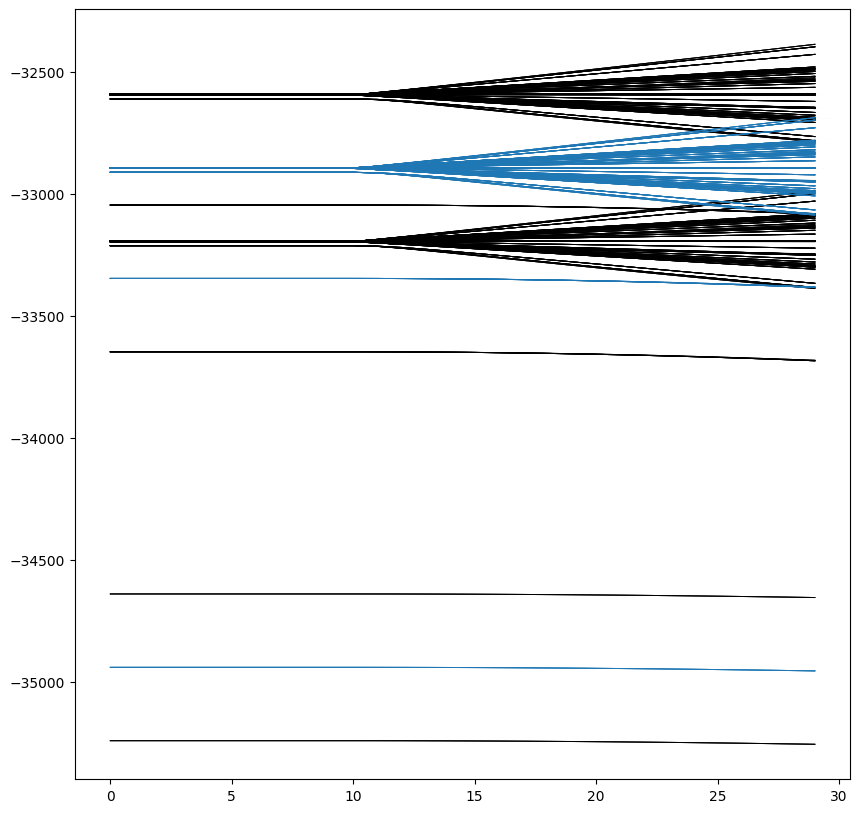

In [80]:
#increase figure size
plt.figure(figsize=(10, 10))
for i in range(es.shape[-1]):
    state = states[i]
    state = states_gen[inverse_map[i]]

    if state[-1] == 0:
        plt.plot( es.real[:, i]*conversion_to_wn/10**9, linewidth=0.7, color='tab:blue', zorder=3, label=state)
    else:
        plt.plot( es.real[:, i]*conversion_to_wn/10**9, linewidth=0.7, color='black', zorder=1, label=state, alpha =0.9)



In [42]:
indx_map

array([  0,   3,   6,   1,   4,   7,   2,   5,   8,  17,  26, 323,  16,
        25, 322,  14,  24, 320,  15,  23, 321,  12,  20, 318,   9,  19,
       319,  11,  18, 316,  13,  21, 317,  10,  22, 315,  39, 338, 626,
        40, 336, 625,  41, 337, 624,  31, 335, 619,  35, 333, 617,  29,
       329, 622,  34, 331, 618,  33, 332, 613,  27, 326, 614,  28, 325,
       615,  30, 324, 620,  32, 328, 616,  38, 334, 623,  36, 330, 621,
        37, 327, 612,  61, 357, 643,  62, 356, 644,  60, 355, 645,  58,
       358, 646,  59, 359, 647,  45, 344, 633,  48, 342, 632,  42, 341,
       630,  46, 345, 629,  44, 340, 631,  43, 339, 627,  47, 343, 628,
        55, 354, 641,  56, 349, 639,  57, 351, 642,  49, 347, 638,  52,
       346, 637,  51, 353, 636,  50, 352, 640,  54, 348, 635,  53, 350,
       634,  88, 384, 674,  89, 383, 673,  84, 386, 672,  83, 382, 671,
        87, 380, 670,  86, 385, 669,  85, 381, 668,  63, 362, 649,  64,
       368, 655,  70, 366, 651,  66, 365, 650,  71, 363, 648,  6

In [46]:
a = indx_map

In [45]:
b= vectorized_process_states(vs)

In [47]:
a-b

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,

In [51]:
es_a

array([[-0.0053565 , -0.0053565 , -0.0053565 , ..., -0.00495435,
        -0.00495435, -0.00495435],
       [-0.0053565 , -0.0053565 , -0.0053565 , ..., -0.00495435,
        -0.00495435, -0.00495435],
       [-0.0053565 , -0.0053565 , -0.0053565 , ..., -0.00495435,
        -0.00495435, -0.00495435],
       ...,
       [-0.00535828, -0.00535828, -0.00535828, ..., -0.0049671 ,
        -0.00496847, -0.00495435],
       [-0.0053585 , -0.0053585 , -0.0053585 , ..., -0.00496785,
        -0.0049693 , -0.00495435],
       [-0.00535873, -0.00535873, -0.00535873, ..., -0.0049686 ,
        -0.00497013, -0.00495435]], shape=(30, 900), dtype=float32)

In [54]:
np.mean(es_x - es_a)

np.float32(0.0)

In [81]:
!pip install mlx


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.9/31.9 MB 36.0 MB/s eta 0:00:00a 0:00:01


In [7]:
import mlx.core as mx

In [21]:
A_mx = mx.array(h, dtype=mx.float32)
eigvals_mx, eigvecs_mx = mx.linalg.eig(A_mx, stream=mx.cpu)

In [20]:
eigvals, eigvecs = np.linalg.eig(h)

In [24]:
eigvals_mx.numpy()

AttributeError: 'array' object has no attribute 'numpy'

In [23]:
eigvecs_mx

array([[-1+0j, -6.76675e-09+0j, 6.12489e-10+0j, ..., 0+0j, 0+0j, 0+0j],
       [-1.28377e-07+0j, 0.89423+0j, -0.000111656+0j, ..., 0+0j, 0+0j, 0+0j],
       [-1.95829e-08+0j, 3.89348e-05+0j, 1.11879e-05+0j, ..., 0+0j, 0+0j, 0+0j],
       ...,
       [0+0j, 0+0j, 0+0j, ..., 1+0j, 0+0j, 0+0j],
       [0+0j, 0+0j, 0+0j, ..., 0+0j, 1+0j, 0+0j],
       [0+0j, 0+0j, 0+0j, ..., 0+0j, 0+0j, 1+0j]], dtype=complex64)

In [26]:
!pip install torch

/Users/lukebrown/opt/anaconda3/envs/willow/lib/python3.11/pty.py:89: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.6/68.6 MB 34.6 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 31.3 MB/s eta 0:00:00


In [ ]:

"""
    auction_lap.py
    
    From
        https://dspace.mit.edu/bitstream/handle/1721.1/3265/P-2108-26912652.pdf;sequence=1
"""

from __future__ import print_function, division

import sys
import torch

def auction_lap(X, eps=None, compute_score=True):
    """
        X: n-by-n matrix w/ integer entries
        eps: "bid size" -- smaller values means higher accuracy w/ longer runtime
    """
    eps = 1 / X.shape[0] if eps is None else eps
    
    # --
    # Init
    
    cost     = torch.zeros((1, X.shape[1]))
    curr_ass = torch.zeros(X.shape[0]).long() - 1
    bids     = torch.zeros(X.shape)
    
    if X.is_cuda:
        cost, curr_ass, bids = cost.cuda(), curr_ass.cuda(), bids.cuda()
    
    counter = 0
    while (curr_ass == -1).any():
        counter += 1
        
        # --
        # Bidding
        
        unassigned = (curr_ass == -1).nonzero().squeeze()
        
        value = X[unassigned] - cost
        top_value, top_idx = value.topk(2, dim=1)
        
        first_idx = top_idx[:,0]
        first_value, second_value = top_value[:,0], top_value[:,1]
        
        bid_increments = first_value - second_value + eps
        
        bids_ = bids[unassigned]
        bids_.zero_()
        bids_.scatter_(
            dim=1,
            index=first_idx.contiguous().view(-1, 1),
            src=bid_increments.view(-1, 1)
        )
        
        # --
        # Assignment
        
        have_bidder = (bids_ > 0).int().sum(dim=0).nonzero()
        
        high_bids, high_bidders = bids_[:,have_bidder].max(dim=0)
        high_bidders = unassigned[high_bidders.squeeze()]
        
        cost[:,have_bidder] += high_bids
        
        curr_ass[(curr_ass.view(-1, 1) == have_bidder.view(1, -1)).sum(dim=1)] = -1
        curr_ass[high_bidders] = have_bidder.squeeze()
    
    score = None
    if compute_score:
        score = int(X.gather(dim=1, index=curr_ass.view(-1, 1)).sum())
    
    return score, curr_ass, counter

In [76]:
from tqdm import tqdm
import time

class LineLoggingTQDM(tqdm):
    def __iter__(self):
        for item in super().__iter__():
            msg = self.format_meter(**self.format_dict)
            tqdm.write(f"{self.desc or ''} | {msg}")
            yield item

# force an update each loop
iterator = LineLoggingTQDM(
    range(10),
    desc="Time to complete eigval diag+shuffle",
    unit="matrix",
    mininterval=0
)

for i in iterator:
    time.sleep(1)  # simulate work

Time to complete eigval diag+shuffle:   0%|          | 0/10 [00:00<?, ?matrix/s]

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:   0%|          | 0/10 [00:00<?, ?matrix/s]


Time to complete eigval diag+shuffle:  10%|█         | 1/10 [00:01<00:09,  1.00s/matrix]

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:  10%|█         | 1/10 [00:01<00:09,  1.00s/matrix]


Time to complete eigval diag+shuffle:  20%|██        | 2/10 [00:02<00:08,  1.01s/matrix]

...

Time to complete eigval diag+shuffle:  80%|████████  | 8/10 [00:08<00:02,  1.01s/matrix]

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:  80%|████████  | 8/10 [00:08<00:02,  1.01s/matrix]


Time to complete eigval diag+shuffle:  90%|█████████ | 9/10 [00:09<00:01,  1.01s/matrix]

Time to complete eigval diag+shuffle | Time to complete eigval diag+shuffle:  90%|█████████ | 9/10 [00:09<00:01,  1.01s/matrix]


Time to complete eigval diag+shuffle: 100%|██████████| 10/10 [00:10<00:00,  1.01s/matrix]


In [2]:
!pip install jaxopt

In [5]:
!pip install optax

In [1]:
# Copyright 2025 The Scenic Authors.
#
# Licensed under the Apache License, Version 2.0 (the "License");
# you may not use this file except in compliance with the License.
# You may obtain a copy of the License at
#
#     http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing, software
# distributed under the License is distributed on an "AS IS" BASIS,
# WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
# See the License for the specific language governing permissions and
# limitations under the License.

"""JAX-based Hungarian matcher implementation."""

import jax
import jax.numpy as jnp


def hungarian_single(cost):
  """Hungarian matcher for a single example."""

  is_transpose = cost.shape[0] > cost.shape[1]
  if is_transpose:
    cost = cost.T

  n, m = cost.shape
  one_hot_m = jnp.eye(m + 1)

  def row_scan_fn(state, i):
    """Loop over the rows of the cost matrix."""
    u, v, parent = state

    # parent[0] = i; note that i runs from 1 to n inclusive
    parent = jax.lax.dynamic_update_index_in_dim(parent, i, 0, axis=0)

    def dfs_body_fn(state):
      # Row potential, column potential, used array, support array, path array
      # column index j0.
      u, v, used, minv, way, j0 = state

      # Mark column as used
      # used = jax.lax.dynamic_update_index_in_dim(used, True, j0, axis=0)
      # used = jnp.logical_or(used, jnp.arange(m + 1) == j0)
      used = jnp.logical_or(used, one_hot_m[j0])
      used_slice = used[1:]

      # Row paired to column j0
      i0 = parent[j0]

      # Update minv and path to it
      cur = cost[i0 - 1, :] - u[i0] - v[1:]
      cur = jnp.where(used_slice, jnp.full_like(cur, 1e10), cur)
      way = jnp.where(cur < minv, jnp.full_like(way, j0), way)
      minv = jnp.where(cur < minv, cur, minv)

      # When finding an index with minimal minv, we need to mask out the visited
      # rows
      masked_minv = jnp.where(used_slice, jnp.full_like(minv, 1e10), minv)
      j1 = jnp.argmin(masked_minv) + 1
      delta = jnp.min(minv, initial=1e10, where=jnp.logical_not(used_slice))

      # Update potentials
      indices = jnp.where(used, parent, n + 1)  # deliberately out of bounds
      u = u.at[indices].add(delta)
      v = jnp.where(used, v - delta, v)
      minv = jnp.where(jnp.logical_not(used_slice), minv - delta, minv)

      return (u, v, used, minv, way, j1)

    def dfs_cond_fn(state):
      _, _, _, _, _, j0 = state
      return parent[j0] != 0

    # Run the inner while loop (i.e. DFS)
    way = jnp.zeros((m,), dtype=jnp.int32)
    used = jnp.zeros((m + 1,), dtype=jnp.bool_)
    minv = jnp.full((m,), 1e10, dtype=jnp.float32)
    init_state = (u, v, used, minv, way, 0)

    state = jax.lax.while_loop(dfs_cond_fn, dfs_body_fn, init_state)
    u, v, _, _, way, j0 = state

    def update_parent_body_fn(state):
      """Update parents based on the DFS path."""
      parent, j0 = state
      j1 = way[j0 - 1]
      parent = jax.lax.dynamic_update_index_in_dim(
          parent, parent[j1], j0, axis=0)
      return (parent, j1)

    def update_parent_cond_fn(state):
      """Condition function counterpart."""
      _, j0 = state
      return j0 != 0

    # Backtrack the DFS path
    init_state = (parent, j0)
    parent, _ = jax.lax.while_loop(
        update_parent_cond_fn, update_parent_body_fn, init_state)

    return (u, v, parent), None

  # Define the initial state
  u = jnp.zeros((n + 2,), dtype=jnp.float32)
  v = jnp.zeros((m + 1,), dtype=jnp.float32)
  parent = jnp.zeros((m + 1,), dtype=jnp.int32)

  init_state = (u, v, parent)
  (u, v, parent), _ = jax.lax.scan(
      row_scan_fn, init_state, jnp.arange(1, n + 1))

  # -v[0] is the matching cost, but not returned to match the signature all
  # other matchers.
  if n != m:
    # This is a costly operation, so skip it when possible (i.e. for square cost
    # matrices).
    parent, indices = jax.lax.top_k(parent[1:], n)
  else:
    parent, indices = parent[1:], jnp.arange(n)
  parent = parent - 1  # Switch back to 0-based indexing.

  if is_transpose:
    return jnp.stack([indices, parent], axis=0)
  return jnp.stack([parent, indices], axis=0)



def hungarian_scan(cost):
  """A scan-based batch version of the hungarian matching."""
  def hungarian_fn(_, cost):
    return None, hungarian_single(cost)
  _, indices = jax.lax.scan(hungarian_fn, None, cost, unroll=1)
  return indices


hungarian_tpu_matcher = jax.jit(jax.vmap(hungarian_single))
hungarian_scan_tpu_matcher = jax.jit(hungarian_scan)

In [8]:
import jax
import jax.numpy as jnp



# --- Example Usage ---
# You can now JIT this function and use it.
# cost_jax = jnp.array(...)
# hungarian_jit = jax.jit(hungarian_single_sorted)
# row_ind, col_ind = hungarian_jit(cost_jax)
# `row_ind` will be [0, 1, 2, ...] and `col_ind` will be the corresponding columns.
import jax
import jax.numpy as jnp

def hungarian_single_sorted(cost):
  """
  JAX-based Hungarian matcher for a single square cost matrix.

  This function is a modification of the Scenic/Optax implementation that
  returns the assignment with row indices sorted 0 to n-1, matching the
  output format of `scipy.optimize.linear_sum_assignment`.

  Args:
    cost: An [n, n] square cost matrix.

  Returns:
    A tuple of two JAX arrays: (row_indices, col_indices).
    - row_indices: Sorted indices of rows, will be `[0, 1, ..., n-1]`.
    - col_indices: The column index assigned to each corresponding row.
  """
  # For simplicity and performance, this version assumes a square matrix.
  # The original handles rectangular matrices, but that adds complexity.
  n, m = cost.shape
  assert n == m, "This simplified function requires a square cost matrix."

  one_hot_m = jnp.eye(m + 1)

  def row_scan_fn(state, i):
    """Main loop over the rows of the cost matrix."""
    u, v, parent = state
    parent = jax.lax.dynamic_update_index_in_dim(parent, i, 0, axis=0)

    def dfs_body_fn(state):
      """Inner loop body to find an augmenting path (DFS)."""
      u, v, used, minv, way, j0 = state
      used = jnp.logical_or(used, one_hot_m[j0])
      used_slice = used[1:]
      i0 = parent[j0]
      cur = cost[i0 - 1, :] - u[i0] - v[1:]
      cur = jnp.where(used_slice, jnp.full_like(cur, 1e10), cur)
      way = jnp.where(cur < minv, jnp.full_like(way, j0), way)
      minv = jnp.where(cur < minv, cur, minv)
      masked_minv = jnp.where(used_slice, jnp.full_like(minv, 1e10), minv)
      j1 = jnp.argmin(masked_minv) + 1
      delta = jnp.min(minv, initial=1e10, where=jnp.logical_not(used_slice))
      indices = jnp.where(used, parent, n + 1)
      u = u.at[indices].add(delta)
      v = jnp.where(used, v - delta, v)
      minv = jnp.where(jnp.logical_not(used_slice), minv - delta, minv)
      return (u, v, used, minv, way, j1)

    def dfs_cond_fn(state):
      """Inner loop condition."""
      _, _, _, _, _, j0 = state
      return parent[j0] != 0

    way = jnp.zeros((m,), dtype=jnp.int64)
    used = jnp.zeros((m + 1,), dtype=jnp.bool_)
    minv = jnp.full((m,), 1e10, dtype=cost.dtype)
    init_state = (u, v, used, minv, way, 0)
    state = jax.lax.while_loop(dfs_cond_fn, dfs_body_fn, init_state)
    u, v, _, _, way, j0 = state

    def update_parent_body_fn(state):
      """Backtrack the DFS path to update assignments."""
      parent, j0 = state
      j1 = way[j0 - 1]
      parent = jax.lax.dynamic_update_index_in_dim(
          parent, parent[j1], j0, axis=0)
      return (parent, j1)

    def update_parent_cond_fn(state):
      """Backtracking condition."""
      _, j0 = state
      return j0 != 0

    init_state = (parent, j0)
    parent, _ = jax.lax.while_loop(
        update_parent_cond_fn, update_parent_body_fn, init_state)
    return (u, v, parent), None

  # --- Initial state and main algorithm execution ---
  u = jnp.zeros((n + 2,), dtype=cost.dtype)
  v = jnp.zeros((m + 1,), dtype=cost.dtype)
  parent = jnp.zeros((m + 1,), dtype=jnp.int64)
  init_state = (u, v, parent)
  (u, v, parent), _ = jax.lax.scan(
      row_scan_fn, init_state, jnp.arange(1, n + 1))

  # --- Result Processing: Convert to sorted row format ---
  # After the scan, `parent[j]` holds the 1-based row assigned to column `j`.
  # We convert this col->row mapping into the desired row->col mapping.
  
  # Get the 0-based row assigned to each column.
  col_to_row_assignment = parent[1:] - 1
  
  # The row indices are already sorted by definition.
  row_indices = jnp.arange(n)
  
  # Create the column index array by scattering the column numbers
  # into the positions specified by their assigned rows.
  col_indices = jnp.zeros(n, dtype=jnp.int64).at[col_to_row_assignment].set(jnp.arange(m))

  return row_indices, col_indices

# --- Example Usage ---
# You can now JIT this function and use it.
# cost_jax = jnp.array(...)
# hungarian_jit = jax.jit(hungarian_single_sorted)
# row_ind, col_ind = hungarian_jit(cost_jax)
# `row_ind` will be [0, 1, 2, ...] and `col_ind` will be the corresponding columns.

In [14]:
import time
import numpy as np
from scipy.optimize import linear_sum_assignment

import jax
import jax.numpy as jnp
from jax import device_put, jit, block_until_ready
jax.config.update("jax_enable_x64", True)
# pip install jaxopt if you haven’t already
import optax


# problem size
N = 20000
rng = np.random.RandomState(10)
cost_np = rng.rand(N, N).astype(np.float64)
#cost_np = distance

print(f"Benchmarking assignment solvers on {N}×{N} cost matrix\n")

# 1) SciPy
start = time.perf_counter()
row, col = linear_sum_assignment(cost_np)
dt = time.perf_counter() - start
print(f"SciPy             : {dt:.3f} s")



cost_jax = jnp.array(cost_np)
# optax_jit = jit(optax.assignment.hungarian_algorithm)
# start = time.perf_counter()
# row_optax, col_optax = optax_jit(cost_jax)
# row_optax_np, col_optax_np = np.array(row_optax), np.array(col_optax)
# col_optax_by_row = jnp.full((cost_jax.shape[0],), -1, dtype=col_optax.dtype).at[row_optax].set(col_optax)
# dt = time.perf_counter() - start
# print(f"Optax             : {dt:.3f} s")


hungarian_single_jit = jit(hungarian_single_sorted)
start = time.perf_counter()
i, j =  hungarian_single_jit(cost_jax)
dt = time.perf_counter() - start
print(f"JAX             : {dt:.3f} s")



Benchmarking assignment solvers on 30000×30000 cost matrix

SciPy             : 114.994 s
JAX             : 0.224 s


In [10]:
print("Row indices equal?  ", np.array_equal(row, np.array(i)))

Row indices equal?   True


In [11]:
print("Row indices equal?  ", np.array_equal(col, np.array(j)))

Row indices equal?   True


In [73]:
row_optax_np, col_optax_np = np.array(row_optax), np.array(col_optax)
print("Same pairs? ", set(zip(row, col)) == set(zip(row_optax_np, col_optax_np)))

Same pairs?  True


In [66]:
cost_scipy = cost_np[row, col].sum()
cost_scipy

np.float64(30.62114315758412)

In [74]:
order = np.argsort(row_optax_np)

In [75]:
print("Row equal after sort? ", np.array_equal(row, row_optax_np[order]))
print("Col equal after sort? ", np.array_equal(col, col_optax_np[order]))


Row equal after sort?  True
Col equal after sort?  True


In [65]:
cost_optax = cost_jax[row_optax, col_optax].sum().item()
cost_optax

30.62114315758412

In [51]:
col

array([  1,   0,   2,   4,   3,   5,   6,   7,   8,  11,  10,   9,  14,
        13,  12,  16,  19,  17,  18,  15,  21,  20,  22,  23,  28,  24,
        26,  27,  25,  31,  29,  30,  32,  37,  33,  34,  35,  36,  39,
        38,  40,  41,  42,  43,  44,  46,  45,  49,  48,  47,  50,  55,
        52,  53,  54,  51,  57,  58,  56,  59,  61,  62,  64,  60,  63,
        65,  66,  68,  70,  69,  71,  67,  72,  73,  74,  76,  78,  75,
        77,  80,  79,  81,  84,  85,  82,  86,  83,  87,  89,  88,  92,
        95,  94,  90,  91,  96,  93,  97,  99,  98, 101, 100, 102, 104,
       103, 108, 105, 106, 109, 110, 111, 107, 115, 114, 116, 113, 112,
       117, 119, 118, 122, 120, 121, 124, 125, 123, 126, 127, 128, 130,
       129, 131, 133, 134, 132, 137, 136, 135, 139, 138, 141, 140, 142,
       143, 145, 144, 146, 150, 147, 149, 148, 151, 152, 153, 154, 155,
       157, 156, 158, 160, 159, 162, 161, 166, 164, 165, 167, 163, 168,
       169, 170, 171, 172, 174, 173, 176, 175, 178, 179, 177, 18

In [50]:
j_op

Array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [48]:
row

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [43]:
cost_optax = cost_jax[i_op, j_op].sum().item()
cost_optax

30.621145248413086

In [39]:
row

array([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,
        13,  14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,
        26,  27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,
        39,  40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,
        52,  53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,
        65,  66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,
        78,  79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,
        91,  92,  93,  94,  95,  96,  97,  98,  99, 100, 101, 102, 103,
       104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116,
       117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129,
       130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142,
       143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155,
       156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168,
       169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18

In [40]:
i

Array([  1,   0,   2,   4,   3,   5,   6,   7,   8,  11,  10,   9,  14,
        13,  12,  19,  15,  17,  18,  16,  21,  20,  22,  23,  25,  28,
        26,  27,  24,  30,  31,  29,  32,  34,  35,  36,  37,  33,  39,
        38,  40,  41,  42,  43,  44,  46,  45,  49,  48,  47,  50,  55,
        52,  53,  54,  51,  58,  56,  57,  59,  63,  60,  61,  64,  62,
        65,  66,  71,  67,  69,  68,  70,  72,  73,  74,  77,  75,  78,
        76,  80,  79,  81,  84,  86,  82,  83,  85,  87,  89,  88,  93,
        94,  90,  96,  92,  91,  95,  97,  99,  98, 101, 100, 102, 104,
       103, 106, 107, 111, 105, 108, 109, 110, 116, 115, 113, 112, 114,
       117, 119, 118, 121, 122, 120, 125, 123, 124, 126, 127, 128, 130,
       129, 131, 134, 132, 133, 137, 136, 135, 139, 138, 141, 140, 142,
       143, 145, 144, 146, 148, 150, 149, 147, 151, 152, 153, 154, 155,
       157, 156, 158, 160, 159, 162, 161, 167, 164, 165, 163, 166, 168,
       169, 170, 171, 172, 174, 173, 176, 175, 179, 177, 178, 18

In [13]:
col

array([ 9,  0, 10,  2,  5,  4,  3,  1, 11,  8,  7,  6])

In [14]:
i_op

Array([ 1,  7,  3,  6,  5,  4, 11, 10,  9,  0,  2,  8], dtype=int32)

In [1]:
import time
import numpy as np
from scipy.optimize import linear_sum_assignment

import jax
import jax.numpy as jnp
from jax import device_put, jit, block_until_ready

# pip install jaxopt if you haven’t already
import optax


# problem size
N = 20
rng = np.random.RandomState(0)
cost_np = rng.rand(N, N).astype(np.float32)

print(f"Benchmarking assignment solvers on {N}×{N} cost matrix\n")

# 1) SciPy
start = time.perf_counter()
row, col = linear_sum_assignment(cost_np)
dt = time.perf_counter() - start
print(f"SciPy             : {dt:.3f} s")



cost_jax = jnp.array(cost_np)
optax_jit = jit(optax.assignment.hungarian_algorithm)
start = time.perf_counter()
i, j = optax_jit(cost_jax)
dt = time.perf_counter() - start
print(f"Optax             : {dt:.3f} s")


hungarian_single_jit = jit(hungarian_single)
start = time.perf_counter()
i_j, j_j =  hungarian_single_jit(cost_jax)
dt = time.perf_counter() - start
print(f"JAX             : {dt:.3f} s")



Benchmarking assignment solvers on 20×20 cost matrix

SciPy             : 0.000 s
Optax             : 0.107 s


NameError: name 'hungarian_single' is not defined

In [ ]:
import time
import numpy as np
from scipy.optimize import linear_sum_assignment

import jax
import jax.numpy as jnp
from jax import device_put, jit, block_until_ready

import mlx.core as mx  # type: ignore
import scipy.linalg
# pip install jaxopt if you haven’t already
import optax


# problem size
# N = 30000
# rng = np.random.RandomState(0)
# cost_np = rng.rand(N, N).astype(np.float32)
cost_np = h2
print(f"Benchmarking assignment solvers on {N}×{N} cost matrix\n")


cost_jax = jnp.array(cost_np)
# hungarian_single_jit = jnp.linalg.eigh
# start = time.perf_counter()
# i_j, j_j =  hungarian_single_jit(cost_jax)
# dt = time.perf_counter() - start
# print(f"JAX             : {dt:.3f} s")


hungarian_single_jit = jit(jnp.linalg.eigh)
start = time.perf_counter()
i_j, j_j =  hungarian_single_jit(cost_jax)
dt = time.perf_counter() - start
print(f"JAX             : {dt:.3f} s")
 

cost_mx = mx.array(cost_np, dtype=mx.float64)
start = time.perf_counter()
u, v = mx.linalg.eigh(cost_mx, stream=mx.cpu)
dt = time.perf_counter() - start
print(f"MLX             : {dt:.3f} s")

#scipy
# start = time.perf_counter()
# u,v = scipy.linalg.eigh(cost_np)


Benchmarking assignment solvers on 30000×30000 cost matrix

JAX             : 0.024 s
JAX             : 0.029 s
MLX             : 0.001 s


In [68]:
# dt = time.perf_counter() - start
# print(f"SciPy             : {dt:.3f} s")
del u, v, i_j, j_j, cost_mx, cost_jax, cost_np

In [9]:
import time
import numpy as np
from scipy.optimize import linear_sum_assignment

import jax
import jax.numpy as jnp
from jax import device_put, jit, block_until_ready

import mlx.core as mx  # type: ignore
import scipy.linalg
# pip install jaxopt if you haven’t already
import optax


In [11]:
cost_np = h2
cost_jax = jnp.array(cost_np)


In [14]:
h2.shape

(37500, 37500)

In [12]:
hungarian_single_jit = jit(jnp.linalg.eigh)

In [17]:
start = time.perf_counter()
i_j, j_j =  hungarian_single_jit(cost_jax)
dt = time.perf_counter() - start
print(f"JAX             : {dt:.3f} s")

JAX             : 0.001 s


In [ ]:
j_j

In [21]:
cost_mx = mx.array(cost_np, dtype=mx.float64)


In [22]:
start = time.perf_counter()
u, v = mx.linalg.eigh(cost_mx, stream=mx.cpu)
dt = time.perf_counter() - start
print(f"MLX             : {dt:.3f} s")

MLX             : 0.003 s


In [23]:
u[0]

: 

: 

In [61]:
h2.shape

(22500, 22500)

In [44]:
import mlx.core as mx
A = mx.array([[1., -2.], [-2., 1.]])
w, v = mx.linalg.eigh(A, stream=mx.cpu)


In [34]:
i

Array([18, 12, 13, 14, 10, 17,  6,  2,  5, 15, 19,  8, 16, 11,  1,  3,  0,
        4,  9,  7], dtype=int32)

In [36]:
col

array([16, 14,  7, 15, 17,  8,  6, 19, 11, 18,  4, 13,  1,  2,  3,  9, 12,
        5,  0, 10])

In [37]:
row

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19])

In [35]:
j

Array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19], dtype=int32)

In [28]:
cost_np[np.array(row), np.array(col)].sum()

np.float64(2461.8431382734734)

In [29]:
cost_np[np.array(i), np.array(j)].sum()

np.float64(2461.8431382734734)

In [26]:
j

Array([    0,     1,     2, ..., 11022, 11023, 11024], dtype=int32)

In [27]:
col

array([    0,     1,     2, ..., 11022, 11023, 11024], shape=(11025,))

In [23]:
row

array([    0,     1,     2, ..., 11022, 11023, 11024], shape=(11025,))

In [5]:
i_j[10]

Array([18, 12, 13, 14, 10, 17,  6,  2,  5, 15, 19,  8, 16, 11,  1,  3,  0,
        4,  9,  7], dtype=int32)

In [6]:
col

array([16, 14,  7, 15, 17,  8,  6, 19, 11, 18,  4, 13,  1,  2,  3,  9, 12,
        5,  0, 10])

In [16]:
col 

array([ 4,  2, 10, 11,  7,  9,  3,  8,  1,  5,  6,  0])

In [17]:
# SciPy
row, col = linear_sum_assignment(cost_np)
cost_scipy = cost_np[row, col].sum()

# Optax / JAX
row_jax, col_jax = optax.assignment.hungarian_algorithm(cost_jax)
# force sync if you’re on GPU:
from jax import block_until_ready
block_until_ready(row_jax); block_until_ready(col_jax)
cost_jax_val = cost_np[np.array(row_jax), np.array(col_jax)].sum()

print(cost_scipy, cost_jax_val)  # should be identical

1.5430123 1.5430123
